# 02 · Model evaluation of the frozen `night_4.h5`

No training happens here. This notebook runs the evaluation pipeline (`python -m fraud_ae.evaluate`) and walks through its outputs. Design:

* **Split.** The training notebook used `train_test_split(test_size=0.2, random_state=42)`. Reproducing it gives the *same* 20k validation rows the model never trained on. They are split 50/50 into **calibration** (choose the threshold) and **test** (report metrics), so the threshold is never tuned on the rows it is scored on.
* **Positives.** 2,500 synthetic fraud users, never seen by the model and **never used to pick the threshold**. The threshold is unsupervised: it uses normal data only, as it would in production before any labels exist.
* **Score.** Per-row mean squared reconstruction error over the 52 scaled features.

In [1]:
import sys, warnings; sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from fraud_ae import config
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 60)
SURFACE, INK2, NORMAL_C, FRAUD_C = "#fcfcfb", "#52514e", "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "font.size": 9})
import json, subprocess, os
from IPython.display import Image, display
r = subprocess.run([sys.executable, "-m", "fraud_ae.evaluate"], cwd="..", env={**os.environ, "PYTHONPATH": "src"}, capture_output=True, text=True)
assert r.returncode == 0, r.stderr[-2000:]
m = json.load(open("../reports/metrics.json"))
pd.DataFrame(m["score_summary"]).T

,median,p99,max
train,0.032968,0.058039,0.073512
cal,0.033309,0.057828,0.076890
test,0.033222,0.058049,0.075200
fraud,12.341194,19.043756,21.090401


Train-sample, calibration and test normals have the **same** error distribution (median ≈ 0.033): no overfitting. Fraud errors are ~370× larger (median ≈ 12).

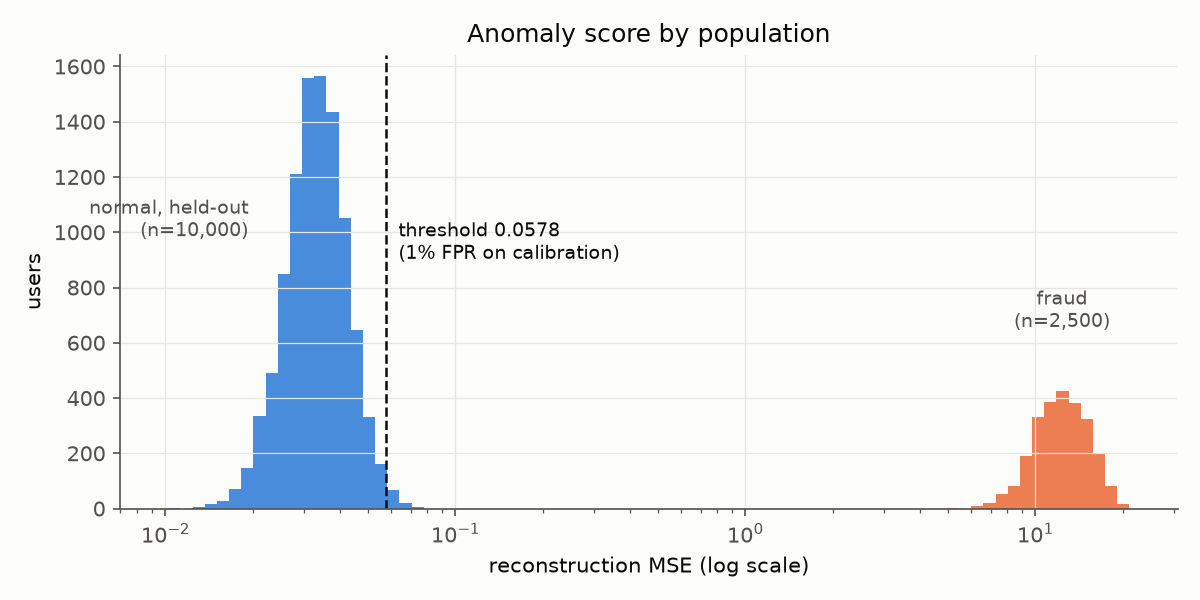

ROC-AUC 1.0000 | Average precision 1.0000 | IsolationForest baseline ROC-AUC 0.999999


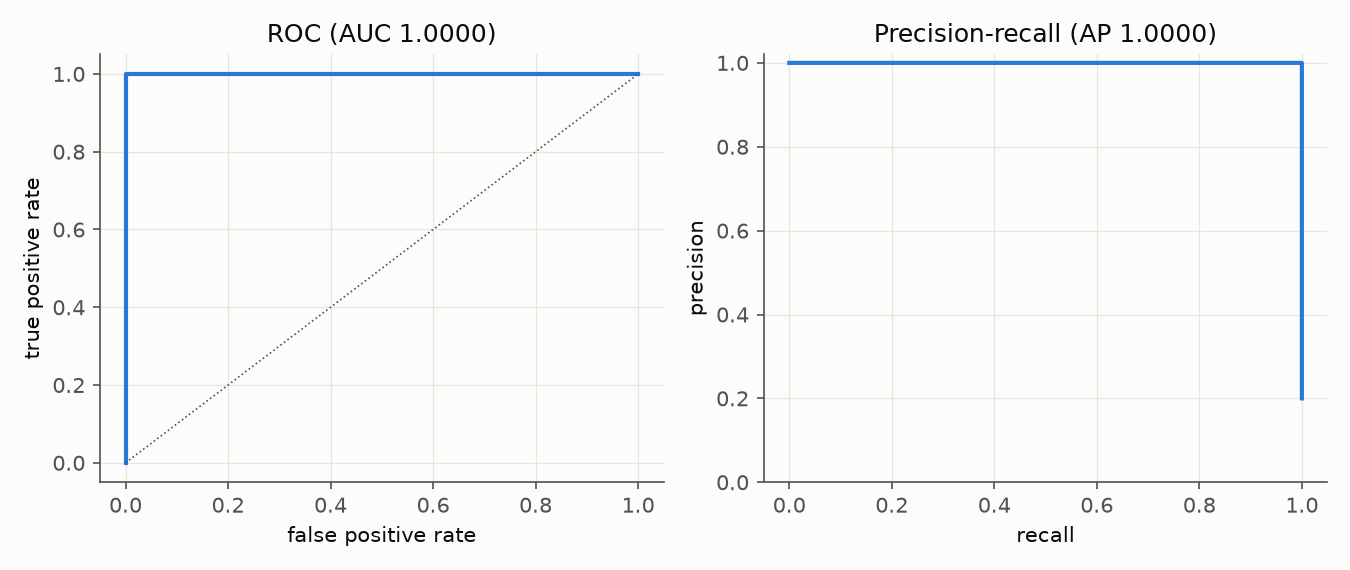

In [2]:
display(Image("../docs/figures/score_distribution.png"))
print(f"ROC-AUC {m['roc_auc']:.4f} | Average precision {m['average_precision']:.4f} | IsolationForest baseline ROC-AUC {m['baseline_isolation_forest_roc_auc']:.6f}")
display(Image("../docs/figures/roc_pr.png"))

**Reading this honestly.** AUC = 1.0 does not mean the model is excellent. It means the benchmark is *saturated*: an untuned IsolationForest also scores ≈ 1.0, as the EDA predicted. On this data, ranking quality cannot distinguish models. What matters operationally is the **false-positive rate on normal users** (alert volume), which is set by the threshold.

## Threshold selection

In [3]:
t = pd.DataFrame(m["thresholds"]).T
t.style.format({"threshold": "{:.4f}", "fpr_normal_test": "{:.2%}", "recall_fraud": "{:.1%}", "precision_at_1%_prevalence": "{:.1%}"})

,threshold,fpr_normal_test,recall_fraud,precision_at_1%_prevalence
fixed_0.05 (third.ipynb),0.0500,4.30%,100.0%,19.0%
p96 (api.py),0.0506,3.80%,100.0%,21.0%
tukey_1.5IQR (third(1).ipynb),0.0555,1.62%,100.0%,38.4%
median+3MAD,0.0496,4.51%,100.0%,18.3%
skew_adjusted_percentile,0.0472,6.75%,100.0%,13.0%
quantile_fpr1% (adopted),0.0578,1.04%,100.0%,49.3%


Every rule catches 100% of fraud, so the choice is purely about how many normal users get flagged:

* `fixed 0.05` (hackathon notebook) and `p96` (hackathon API) flag **4-4.5%** of normal users. At a realistic 1% fraud prevalence that is roughly 4 false alarms per real fraud.
* The `p96` rule is also *batch-relative*: it flags 4% of **any** upload, even one with zero fraud or 100% fraud. See the skew section below.
* **Adopted:** `quantile` at a **1% target FPR on calibration normals**, which gives 1.04% FPR on unseen test normals (well calibrated) and ~49% precision at 1% prevalence. The 1% is a business knob (analyst capacity), not a statistical truth. It is stored in `models/threshold.json` with its provenance.

## Model selection across the hackathon checkpoints

In [4]:
pd.DataFrame(m["checkpoints"]).T[["params", "val_mse_normal", "roc_auc", "fpr_normal_test", "recall_fraud", "precision_at_1%_prevalence"]].style.format(
    {"params": "{:,.0f}", "val_mse_normal": "{:.4f}", "roc_auc": "{:.4f}", "fpr_normal_test": "{:.2%}", "recall_fraud": "{:.0%}", "precision_at_1%_prevalence": "{:.1%}"})

,params,val_mse_normal,roc_auc,fpr_normal_test,recall_fraud,precision_at_1%_prevalence
night_4.h5 (shipped),"113,620",0.0340,1.0000,1.04%,100%,49.3%
autoencoder_fraud_detection.h5,"12,036",0.1530,1.0000,1.18%,100%,46.1%
night_1.h5,"4,764",0.0784,1.0000,1.26%,100%,44.5%
night_2.h5,"6,342",0.0694,1.0000,1.17%,100%,46.3%
night_3.h5,"8,402",0.0669,1.0000,1.14%,100%,47.0%


All five checkpoints separate the populations perfectly. `night_4` reconstructs normal users best (lowest val MSE, 0.034 vs 0.067-0.153) and gives the tightest normal-score distribution, hence the lowest FPR at a fixed quantile. It is kept as the production model. *Caveat:* only `night_4`'s preprocessing artifacts survived, and the older checkpoints may have been trained on a differently generated CSV, so their numbers are indicative only.

## Where does the signal come from? (attribution and ablation without retraining)

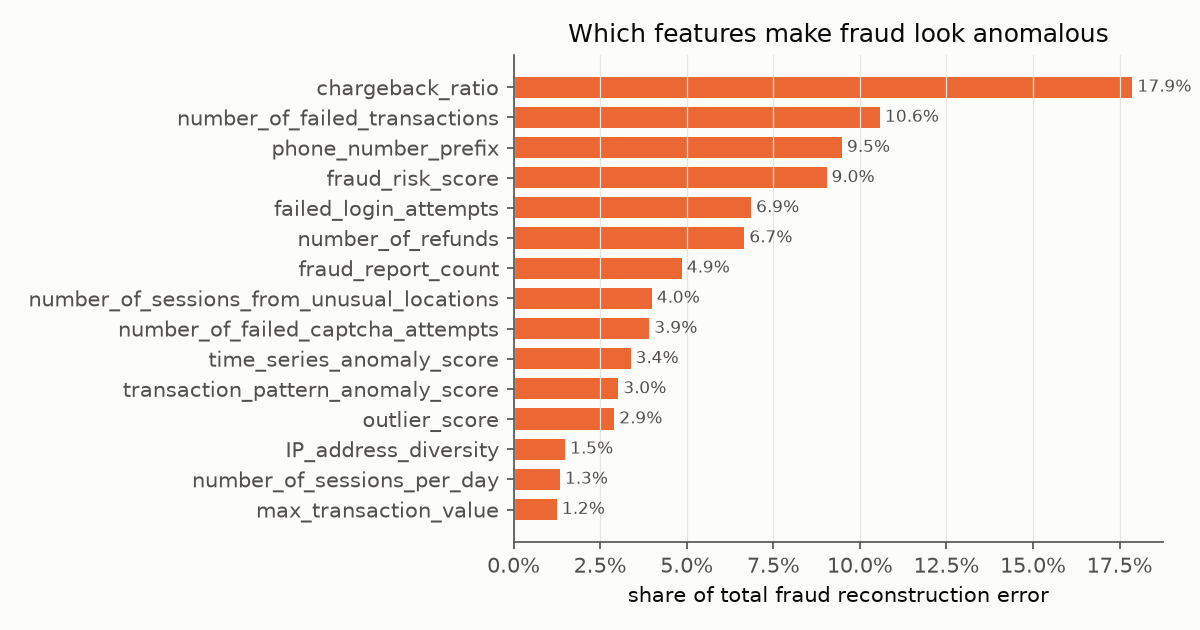

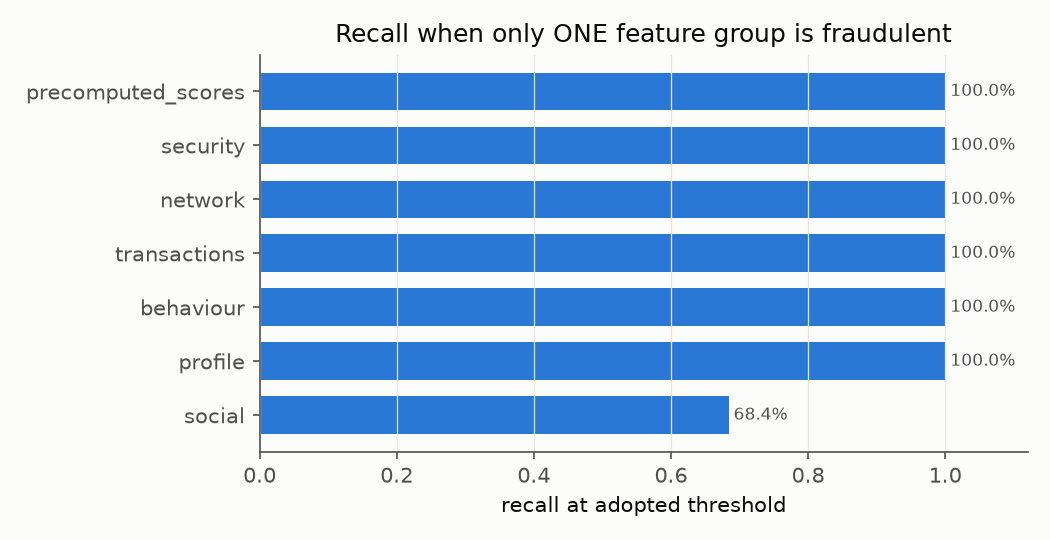

Recall with the 4 pre-computed *_score columns replaced by normal values: 100.0%


In [5]:
display(Image("../docs/figures/feature_attribution.png"))
display(Image("../docs/figures/single_group_recall.png"))
print(f"Recall with the 4 pre-computed *_score columns replaced by normal values: {m['recall_without_precomputed_scores']:.1%}")

In [6]:
sf = pd.Series(m["single_feature_recall"])
print(f"{(sf >= .5).sum()} of 52 features ALONE trigger an alert on >=50% of fraud users"); sf.head(30).to_frame("recall_if_only_this_feature_is_fraudulent").style.format("{:.1%}")

28 of 52 features ALONE trigger an alert on >=50% of fraud users


,recall_if_only_this_feature_is_fraudulent
phone_number_prefix,100.0%
chargeback_ratio,100.0%
number_of_failed_transactions,100.0%
account_suspension_count,100.0%
fraud_report_count,100.0%
outlier_score,100.0%
transaction_pattern_anomaly_score,100.0%
time_series_anomaly_score,100.0%
fraud_risk_score,100.0%
number_of_failed_captcha_attempts,99.6%


Method: take a random *normal* user and overwrite one feature group (or one feature) with a fraud user's values. Then ask whether the frozen model alerts. This is a counterfactual probe; no retraining is needed.

* Each group except `social` is **individually sufficient** for 100% recall, and 28 single features each catch the majority of fraud. The detector is highly redundant, which is good for robustness against a fraudster who disguises a few fields.
* The circular `*_score` features are **not** what the model relies on: recall stays 100% without them.
* Unseen categorical values (`email_domain`, `browser_type`, `payment_methods_used`, `most_active_community`) contribute almost nothing alone. This confirms the EDA concern that label encoding + `-1` fallback mutes categorical novelty.

## The original API's train/serve skew, quantified

In [7]:
print("Uploading fraud_night_1.csv (100% fraud) as call.py did:")
print(json.dumps(m["legacy_api_on_fraud_file"], indent=2))
print("Mixed batch (2,000 normal + 50 fraud):")
print(json.dumps(m["legacy_api_on_mixed_batch"], indent=2))

Uploading fraud_night_1.csv (100% fraud) as call.py did:
{
  "flagged_share_p96_rule": 0.04,
  "flagged_share_frozen_pipeline": 1.0
}
Mixed batch (2,000 normal + 50 fraud):
{
  "fraud_rows": 50,
  "rows": 2050,
  "fraud_caught_p96_refit": 49,
  "fraud_caught_frozen": 50
}


The hackathon API re-fitted `LabelEncoder` + `MinMaxScaler` on each uploaded file and flagged the batch's top 4%. On the demo file of 2,500 fraudsters it would report only **4%** of them, because after per-batch re-scaling the fraudsters look normal *relative to each other*. The rebuilt pipeline applies the training-time transform and a fixed threshold, and flags **100%**. This was the most consequential bug in the original code.

## Conclusions
1. The frozen model is correct, well calibrated on held-out normals, and catches all synthetic fraud at 1% FPR.
2. The benchmark is too easy to rank models. Real-world performance is **unknown**, and the reported numbers are an upper bound.
3. Highest-value next steps (each requires retraining, see `docs/REPORT.md` §9): a hard fraud set that overlaps normal ranges, dropping leaky and circular features, one-hot encoding with novelty flags, account age instead of a date string, and benchmarking against IsolationForest and a per-feature z-score rule.